# Classical Solvers and Physics-Informed Neural Networks for 1-D Nonlinear Conduction

*A warm-up problem with a closed-form solution. It introduces three ways of solving a differential equation (finite differences, finite elements and physics-informed neural networks, PINNs) and benchmarks them against the exact answer.*

---

## 1. Problem statement

Steady heat conduction in a rod $x\in[0,L]$ without internal heat sources:

$$\frac{d}{dx}\left[k(T)\,\frac{dT}{dx}\right] = 0, \qquad k(T) = k_0\,(1+\beta T), \qquad T(0)=0,\quad T(L)=T_R ,$$

with $L=10$, $T_R=5$, $k_0=1$, $\beta=0.4$. The conductivity grows with temperature, so the equation is **nonlinear**, but the material is uniform. That is what makes a closed-form solution possible, and it is the reason this chapter uses its own, simpler rod: from the next chapter on, the material varies in space and reference solutions must come from a numerical solver (see [The Benchmark Problem](benchmark_problem.ipynb)).

## 2. Analytical solution

The flux $q = k(T)\,dT/dx$ is constant along the rod, because its derivative vanishes. Integrating once,

$$k_0\,(1+\beta T)\,\frac{dT}{dx} = C_1 ,$$

and integrating again,

$$k_0\left(T + \tfrac{1}{2}\beta T^2\right) = C_1 x + C_2 .$$

The boundary conditions give $C_2 = 0$ (from $T(0)=0$) and $C_1 = k_0\,(T_R + \tfrac12\beta T_R^2)/L$ (from $T(L)=T_R$). Solving the resulting quadratic for $T$,

$$T(x) = \frac{-1 + \sqrt{1 + 2\beta M(x)}}{\beta}, \qquad M(x) = \frac{T_R + \tfrac12\beta T_R^2}{L}\,x .$$

This exact profile is the reference for every method in this chapter.

## 3. Physics-informed neural network

### 3.1 The residual loss

A PINN represents the solution by a neural network $T_{\text{pred}}(x)$ and trains it to satisfy the differential equation itself. The derivatives are obtained by automatic differentiation (`jax.grad`), and the loss is the mean squared residual at a set of collocation points:

$$\mathcal{L}_{\text{physics}} = \text{MSE}\left( \frac{d}{dx} \left[ k(T_{\text{pred}})\, \frac{dT_{\text{pred}}}{dx} \right] \right).$$

The residual fixes the *shape* of the solution but not the specific scenario. The boundary values must be imposed as well, either **softly**, through an extra penalty

$$\mathcal{L}_{BC} = [T_{\text{pred}}(0) - T_{L}]^2 + [T_{\text{pred}}(L) - T_{R}]^2, \qquad \mathcal{L} = W_1\,\mathcal{L}_{BC} + W_2\,\mathcal{L}_{\text{physics}},$$

with $T_L = T(0) = 0$, or **exactly**, by construction (a hard constraint).

### 3.2 Hard boundary constraints

The prediction is written so that it satisfies the boundary conditions for any network weights:

$$T_{\text{pred}}(x) = \underbrace{T_L + \frac{T_R - T_L}{L}\,x}_{A(x):\ \text{boundary term}} \;+\; \underbrace{x\,(L - x)}_{B(x):\ \text{shaping function}}\cdot\, \text{NN}(x).$$

$A(x)$ interpolates the two boundary values; $B(x)$ vanishes at both ends, so the network only shapes the interior. The boundary error is exactly zero from the first epoch, the loss reduces to $\mathcal{L}_{\text{physics}}$ alone, and no weights $W_1, W_2$ have to be balanced.

### 3.3 Training setup

| Setting | Value |
| :--- | :--- |
| Network | one hidden layer of 20 tanh units, input scaled to $x/L$ |
| Collocation points | 2000, uniform on $[0, L]$ |
| Optimizer | full-batch gradient descent, learning rate $10^{-3}$ |
| Epochs | 2000 |
| Loss | $\mathcal{L}_{\text{physics}}$ only (hard boundary constraints) |

Training Thermal PINN with Hard Constraints...


Epoch 0 | Physics Loss: 7.696197e-03


Epoch 1000 | Physics Loss: 2.723564e-03


Final physics loss: 2.709599e-03 | Max abs. error vs analytical: 1.277e-01


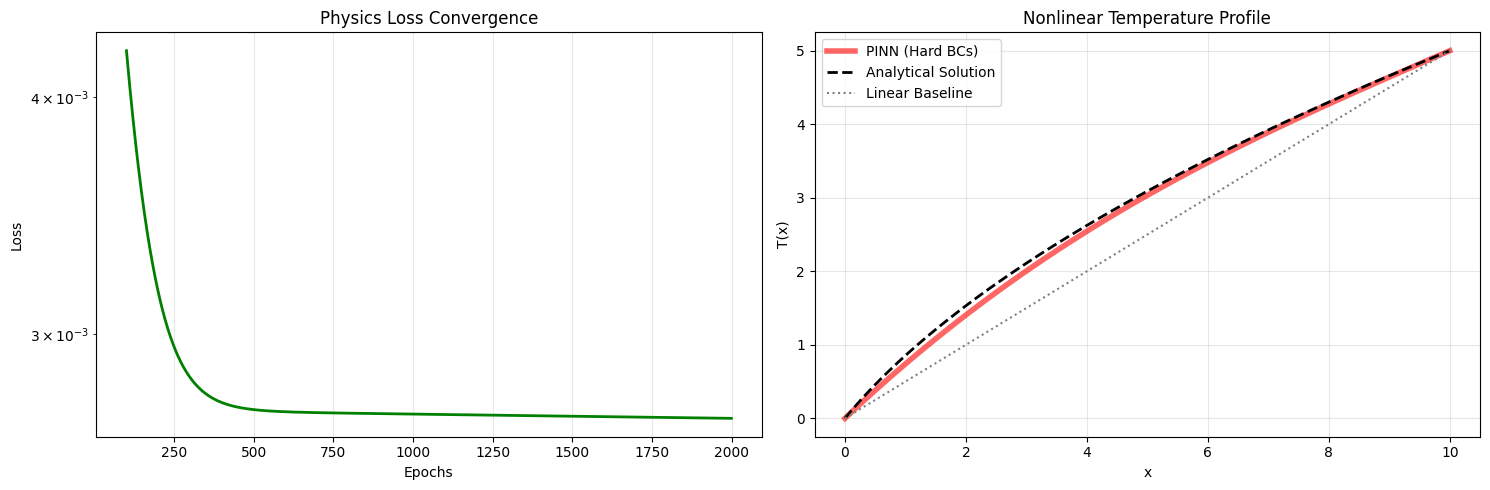

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# --- 1. Physical Constants ---
L = 10.0
T_LEFT = 0.0
T_RIGHT = 5.0
K0 = 1.0
BETA = 0.4

# --- 2. Neural Network & Hard Constraint Transformation ---
def neural_net(params, x):
    W1, b1, W2, b2 = params
    x_scaled = x / L
    hidden = jnp.tanh(jnp.dot(x_scaled, W1) + b1)
    return jnp.dot(hidden, W2) + b2

def T_pred(params, x):
    # A. Boundary Term: Satisfies T(0)=0 and T(10)=5
    boundary_term = (T_RIGHT / L) * x

    # B. Shaping Function: Zero at both x=0 and x=10
    shaping_fn = x * (L - x)

    # C. Neural Network Output
    nn_out = neural_net(params, jnp.array([x]))[0]

    # D. Final Solution (Forced to satisfy BCs)
    return boundary_term + (shaping_fn * nn_out)

# --- 3. Pure Physics Loss Function ---
def loss_fn(params, x_physics):
    # Governing Eq: d/dx( k(T) * dT/dx ) = 0
    # No BC loss needed here because of the Hard Constraint above
    def get_residual(x):
        T = lambda v: T_pred(params, v)
        dT_dx = jax.grad(T)
        k_T = lambda v: K0 * (1.0 + BETA * T(v))
        flux = lambda v: k_T(v) * dT_dx(v)
        return jax.grad(flux)(x)

    physics_residuals = jax.vmap(get_residual)(x_physics)
    return jnp.mean(physics_residuals**2)

# --- 4. Training Loop (full-batch gradient descent, fixed learning rate) ---
k1, k2 = jax.random.split(jax.random.PRNGKey(42))
params = [jax.random.normal(k1, (1, 20)) * 0.2, jnp.zeros(20),
          jax.random.normal(k2, (20, 1)) * 0.1, jnp.zeros(1)]

x_physics = jnp.linspace(0.0, L, 2000)
lr = 0.001
grad_fn = jax.jit(jax.value_and_grad(loss_fn))
history = []

print("Training Thermal PINN with Hard Constraints...")
for epoch in range(2000):

    loss, grads = grad_fn(params, x_physics)
    params = [p - lr * g for p, g in zip(params, grads)]
    history.append(loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch} | Physics Loss: {loss:.6e}")

# --- 5. Analytical Solution & Visualization ---
c1 = (T_RIGHT + 0.5 * BETA * T_RIGHT**2) / L
x_test = jnp.linspace(0, L, 100)
T_analytical = (-1.0 + jnp.sqrt(1.0 + 2.0 * BETA * (c1 * x_test))) / BETA
T_pinn = jax.vmap(T_pred, in_axes=(None, 0))(params, x_test)
print(f"Final physics loss: {history[-1]:.6e} | Max abs. error vs analytical: {jnp.max(jnp.abs(T_pinn - T_analytical)):.3e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot A: Convergence
ax1.plot(range(100, 2000), history[100:], color='green', linewidth=2)
ax1.set_yscale('log')
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.set_title("Physics Loss Convergence")
ax1.grid(True, alpha=0.3)

# Plot B: Result
ax2.plot(x_test, T_pinn, 'r-', label="PINN (Hard BCs)", linewidth=4, alpha=0.6)
ax2.plot(x_test, T_analytical, 'k--', label="Analytical Solution", linewidth=2)
ax2.plot(x_test, 0.5 * x_test, ':', label="Linear Baseline", color='gray')
ax2.set_xlabel("x")
ax2.set_ylabel("T(x)")
ax2.set_title("Nonlinear Temperature Profile")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3.4 Result

The left panel shows the physics loss during training, and the right panel the trained PINN against the analytical solution, with the linear profile as a reference. The loss drops quickly and then **plateaus** after about 500 epochs. The PINN reproduces the nonlinear bending of the profile and meets both boundary values exactly, but a visible gap to the analytical curve remains in the interior (maximum absolute error about 0.13 against the exact solution). With plain gradient descent and a small network, the residual loss stalls before the solution is accurate.

## 4. Benchmark against classical solvers

The PINN is now compared with two classical discretizations of the same problem, on 21 grid points, and with the exact solution.

**Finite differences (FDM).** The equation is discretized on a grid with central differences for the flux at the midpoints between nodes. Because $k(T)$ is nonlinear, the discrete equations are nonlinear too; here they are solved by minimizing the sum of squared discrete residuals (BFGS). Since the conductivity is evaluated at the mean of the two neighboring nodal temperatures and $k$ is linear in $T$, this scheme yields exactly the same discrete equations as the linear finite elements below (2-point Gauss quadrature integrates $k$ exactly). On this problem the two methods therefore differ only in how the nonlinear system is solved.

**Finite elements (FEM).** The rod is split into 20 linear elements. The weak (Galerkin) form is integrated with 2-point Gauss quadrature, and the nonlinear system is solved with **Newton–Raphson** iterations using the consistent tangent matrix. This is the same class of solver that produces the reference solutions for the rest of the book.

**PINN.** For contrast with Section 3, the PINN in this benchmark uses **soft** boundary conditions (loss weights $W_1=500$, $W_2=5000$), 200 collocation points, and 5001 epochs of gradient descent at learning rate $10^{-4}$.

| Method | Discretization | Basis functions | Handling of the nonlinearity |
| :--- | :--- | :--- | :--- |
| **FDM** | point-based grid | none (local differences) | nonlinear optimization |
| **FEM** | element-based | local, piecewise linear | Newton–Raphson iteration |
| **PINN** | mesh-free | global (neural network) | gradient descent on the residual |

**How to read the figure.** The left panel overlays the four solutions. The right panel shows each method's absolute error against the exact solution on a logarithmic scale: FDM and FEM at their grid points, and the PINN on a fine set of test points.

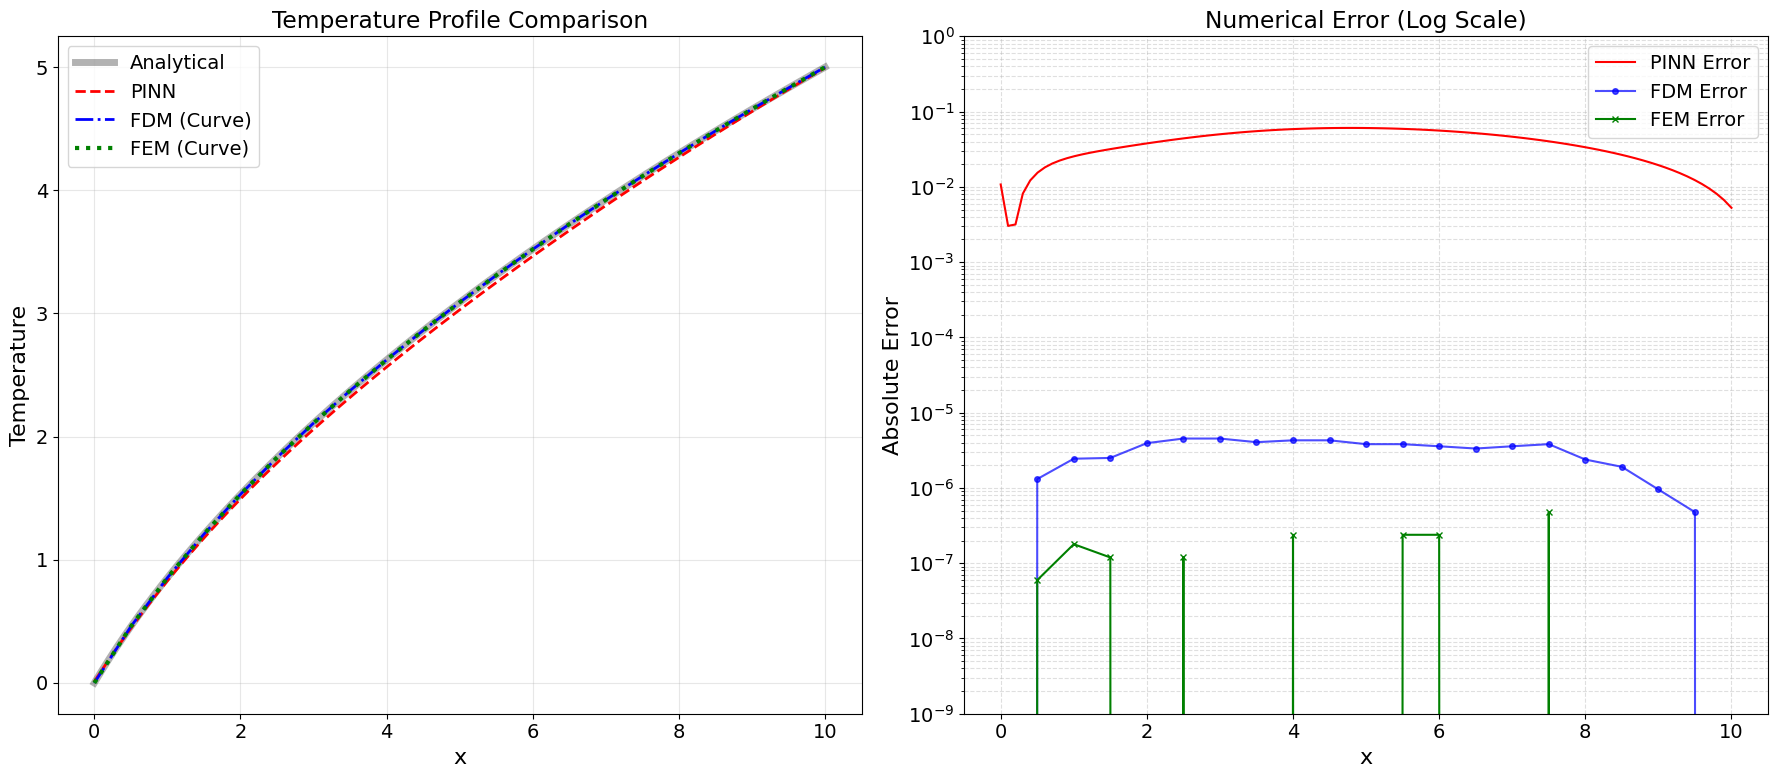

In [2]:
import jax
import jax.numpy as jnp
from jax.scipy.optimize import minimize
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Parameters & Boundary Conditions ---
L = 10.0
T_LEFT = 0.0
T_RIGHT = 5.0
K0 = 1.0
BETA = 0.4
N_ELEMENTS = 20

# --- 2. FDM Solver ---
def solve_fdm(n_points, l, tl, tr, k0, beta):
    dx = l / (n_points - 1)
    x_fdm = jnp.linspace(0, l, n_points)
    def residual(T_internal):
        T = jnp.concatenate([jnp.array([tl]), T_internal, jnp.array([tr])])
        T_mid_plus = (T[1:-1] + T[2:]) / 2.0
        T_mid_minus = (T[1:-1] + T[:-2]) / 2.0
        k_plus = k0 * (1.0 + beta * T_mid_plus)
        k_minus = k0 * (1.0 + beta * T_mid_minus)
        flux_diff = (k_plus * (T[2:] - T[1:-1]) / dx) - (k_minus * (T[1:-1] - T[:-2]) / dx)
        return jnp.sum(flux_diff**2)
    res = minimize(residual, jnp.linspace(tl, tr, n_points-2), method='BFGS')
    T_final = jnp.concatenate([jnp.array([tl]), res.x, jnp.array([tr])])
    return x_fdm, T_final

# --- 3. FEM Solver ---
def solve_fem(n_elements, l, tl, tr, k0, beta):
    nnodes = n_elements + 1
    le = l / n_elements
    x_fem = np.linspace(0, l, nnodes)
    T = np.linspace(tl, tr, nnodes)
    tol, max_iter = 1e-8, 20
    for iteration in range(max_iter):
        K_global, R_global = np.zeros((nnodes, nnodes)), np.zeros(nnodes)
        for e in range(n_elements):
            nodes = [e, e + 1]
            ke, re = np.zeros((2, 2)), np.zeros(2)
            for xi in [-1.0/np.sqrt(3), 1.0/np.sqrt(3)]:
                N = np.array([0.5 * (1 - xi), 0.5 * (1 + xi)])
                B = np.array([-0.5, 0.5]) / (le / 2.0)
                T_gp = N @ T[nodes]
                k = k0 * (1.0 + beta * T_gp)
                T_prime = B @ T[nodes]
                re += (B * k * T_prime) * (le / 2.0)
                ke += (np.outer(B, B) * k + np.outer(B, N) * (k0 * beta) * T_prime) * (le / 2.0)
            for i in range(2):
                R_global[nodes[i]] += re[i]
                for j in range(2): K_global[nodes[i], nodes[j]] += ke[i, j]
        free = np.arange(1, nnodes - 1)
        if np.linalg.norm(R_global[free]) < tol: break
        T[free] += np.linalg.solve(K_global[np.ix_(free, free)], -R_global[free])
    return jnp.array(x_fem), jnp.array(T)

# --- 4. PINN Logic ---
def neural_net(params, x):
    W1, b1, W2, b2 = params
    hidden = jnp.tanh(jnp.dot(x/L, W1) + b1)
    return jnp.dot(hidden, W2) + b2

def T_pred(params, x):
    return neural_net(params, jnp.array([x]))[0]

def loss_fn(params, x_phys):
    loss_bc = (T_pred(params, 0.0) - T_LEFT)**2 + (T_pred(params, L) - T_RIGHT)**2
    def get_res(x):
        T = lambda v: T_pred(params, v)
        dT_dx = jax.grad(T)
        flux = lambda v: K0 * (1.0 + BETA * T(v)) * dT_dx(v)
        return jax.grad(flux)(x)
    return 500.0 * loss_bc + 5000.0 * jnp.mean(jax.vmap(get_res)(x_phys)**2)

# --- 5. Training & Execution ---
x_fdm, T_fdm = solve_fdm(N_ELEMENTS + 1, L, T_LEFT, T_RIGHT, K0, BETA)
x_fem, T_fem = solve_fem(N_ELEMENTS, L, T_LEFT, T_RIGHT, K0, BETA)

k1, k2 = jax.random.split(jax.random.PRNGKey(42))
params = [jax.random.normal(k1, (1, 20)) * 0.2, jnp.zeros(20),
          jax.random.normal(k2, (20, 1)) * 0.1, jnp.zeros(1)]
grad_fn = jax.jit(jax.value_and_grad(loss_fn))
x_phys = jnp.linspace(0.0, L, 200)

for epoch in range(5001):
    loss, grads = grad_fn(params, x_phys)
    params = [p - 0.0001 * g for p, g in zip(params, grads)]

# --- 6. Data Prep ---
c1 = (T_RIGHT + 0.5 * BETA * T_RIGHT**2) / L
x_test = jnp.linspace(0, L, 100)
T_analytical = (-1.0 + jnp.sqrt(1.0 + 2.0 * BETA * (c1 * x_test))) / BETA
T_pinn = jax.vmap(T_pred, in_axes=(None, 0))(params, x_test)

err_pinn = jnp.abs(T_pinn - T_analytical)
err_fdm = jnp.abs(T_fdm - ((-1.0 + jnp.sqrt(1.0 + 2.0 * BETA * (c1 * x_fdm))) / BETA))
err_fem = jnp.abs(T_fem - ((-1.0 + jnp.sqrt(1.0 + 2.0 * BETA * (c1 * x_fem))) / BETA))

# --- 7. Plotting ---
plt.rcParams.update({'font.size': 14, 'axes.labelsize': 16})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# Main Profile: Curves only
ax1.plot(x_test, T_analytical, 'k-', label='Analytical', linewidth=5, alpha=0.3)
ax1.plot(x_test, T_pinn, 'r--', label='PINN', linewidth=2)
ax1.plot(x_fdm, T_fdm, 'b-.', label='FDM (Curve)', linewidth=2)
ax1.plot(x_fem, T_fem, 'g:', label='FEM (Curve)', linewidth=3)

ax1.set_title("Temperature Profile Comparison")
ax1.set_xlabel("x"); ax1.set_ylabel("Temperature")
ax1.legend(); ax1.grid(True, alpha=0.3)

# Error plot
ax2.semilogy(x_test, err_pinn, 'r-', label='PINN Error')
ax2.semilogy(x_fdm, err_fdm, 'b-o', label='FDM Error', markersize=4, alpha=0.7)
ax2.semilogy(x_fem, err_fem, 'g-x', label='FEM Error', markersize=5)

# Lower y-limit so exact zeros on the log scale do not stretch the axis
ax2.set_ylim(1e-9, 1e0)
ax2.set_title("Numerical Error (Log Scale)")
ax2.set_xlabel("x"); ax2.set_ylabel("Absolute Error")
ax2.legend(loc='upper right'); ax2.grid(True, which='both', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 5. Discussion

The two classical solvers are far more accurate than the PINN on this problem. FEM agrees with the exact solution to about $10^{-7}$, the round-off level of single-precision arithmetic. The reason is that the element flux $k_0\bigl(1+\beta\,\tfrac{T_i+T_{i+1}}{2}\bigr)\frac{T_{i+1}-T_i}{h}$ equals the difference of $G(T)=k_0\bigl(T+\tfrac12\beta T^2\bigr)$ between the two nodes divided by $h$, and $G$ is linear in $x$ for the exact solution, so the nodal values of the exact solution satisfy the discrete equations exactly. FDM reaches about $10^{-6}$. Its discrete equations are the same, so this remaining error is not a discretization error: it is the stopping tolerance of the BFGS minimization in single precision, whereas Newton–Raphson drives the residual to round-off. The soft-constrained PINN trained with plain gradient descent stays at about $10^{-2}$ in the interior. It also has a visible error at the boundaries, which the hard-constraint version of Section 3 removes, while the interior error remains in both versions.

Two lessons carry forward into the rest of the book:

- **A physics residual can replace labeled data.** The PINN never saw a solution value, only the equation. The same idea returns in Parts II and III, where the finite-element residual (in weighted-residual form) trains neural operators without labels.
- **One network, one solution.** A PINN solves one instance of the problem. A new material or new boundary conditions mean training from scratch, and each training run is far more expensive than one FEM solve. *Neural operators* instead learn the map from the input (material, initial state) to the solution, so a single trained model answers new instances in one forward pass.

The next chapter, [The Benchmark Problem](benchmark_problem.ipynb), defines the heterogeneous rod, the reference solver and the datasets on which those operators are built.